# Phase 7 — SHAP Explainability

Explain predictions of the final HEAL Logistic Regression model using SHAP to understand global feature importance, directional effects, and individual patient model predictions.

*Frame: Model explainability for a clinical decision-support research prototype (not medical diagnosis or causal inference).*

## 1. Load Data and Final Model
Load the locked NHANES dataset, apply the stratified 80/20 train/test split, and retrain the final Phase 6 Logistic Regression model.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Visual settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

# Load dataset
data_path = "stroke_cleaned_dataset_corrected.csv"
df = pd.read_csv(data_path)

features = ['Systolic_BP', 'Diastolic_BP', 'BMI', 'Diabetes', 'HbA1c', 'Smoker']
target = 'Stroke'

X = df[features].copy()
y = df[target].copy()

# Stratified 80/20 split (random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# StandardScaler fitted strictly on training cohort
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['Systolic_BP', 'Diastolic_BP', 'BMI', 'HbA1c']),
        ('cat', 'passthrough', ['Diabetes', 'Smoker'])
    ]
)

feature_names = ['Systolic_BP', 'Diastolic_BP', 'BMI', 'HbA1c', 'Diabetes', 'Smoker']
X_train_trans = pd.DataFrame(preprocessor.fit_transform(X_train), columns=feature_names)
X_test_trans = pd.DataFrame(preprocessor.transform(X_test), columns=feature_names)

# Final locked Logistic Regression model
clf = LogisticRegression(
    C=1.0,
    solver='liblinear',
    penalty='l2',
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)
clf.fit(X_train_trans, y_train)

print(f"Dataset loaded: {df.shape[0]} rows ({df.shape[1]} columns)")
print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")
print("Final Logistic Regression model retrained successfully.")

Dataset loaded: 6053 rows (8 columns)
Train samples: 4842 | Test samples: 1211
Final Logistic Regression model retrained successfully.


## 2. Verify Features
Confirm feature list, feature order, and model coefficients match the locked Phase 6 model.

In [2]:
print(f"Features: {feature_names}")
print(f"Model Intercept: {clf.intercept_[0]:.4f}")
print("\nModel Coefficients:")
for feat, coef in zip(feature_names, clf.coef_[0]):
    print(f"  {feat:15s}: {coef:+.4f} (Odds Ratio = {np.exp(coef):.4f})")

# Assert consistency
assert len(features) == 6, "Feature count mismatch"
assert len(X_test) == 1211, "Test size mismatch"
assert abs(clf.intercept_[0] - (-0.8576)) < 1e-3, "Model intercept mismatch"
print("\n[OK] Model and feature pipeline match Phase 6 exactly.")

Features: ['Systolic_BP', 'Diastolic_BP', 'BMI', 'HbA1c', 'Diabetes', 'Smoker']
Model Intercept: -0.8576

Model Coefficients:
  Systolic_BP    : +0.4265 (Odds Ratio = 1.5318)
  Diastolic_BP   : -0.1422 (Odds Ratio = 0.8674)
  BMI            : +0.0009 (Odds Ratio = 1.0009)
  HbA1c          : +0.1254 (Odds Ratio = 1.1336)
  Diabetes       : +1.0038 (Odds Ratio = 2.7287)
  Smoker         : +1.0535 (Odds Ratio = 2.8676)

[OK] Model and feature pipeline match Phase 6 exactly.


## 3. Generate SHAP Values
Initialize `shap.LinearExplainer` using the training cohort as background data and compute SHAP values for all test set predictions.

In [3]:
# Initialize LinearExplainer with independent background masker
masker = shap.maskers.Independent(data=X_train_trans, max_samples=len(X_train_trans))
explainer = shap.LinearExplainer(clf, masker=masker)

# Compute SHAP values on test set
exp = explainer(X_test_trans)

# Verify additivity: sum(SHAP) + base_value == model logit
test_logits = clf.decision_function(X_test_trans)
shap_sums = exp.values.sum(axis=1) + exp.base_values
max_diff = np.max(np.abs(test_logits - shap_sums))

print(f"Explainer: {explainer.__class__.__name__}")
print(f"Computed SHAP values for {exp.shape[0]} test samples across {exp.shape[1]} features")
print(f"Base value (expected log-odds): {exp.base_values[0]:.4f}")
print(f"Additivity verification (|logit - SHAP sum| max diff): {max_diff:.2e}")

Explainer: LinearExplainer
Computed SHAP values for 1211 test samples across 6 features
Base value (expected log-odds): -0.2893
Additivity verification (|logit - SHAP sum| max diff): 8.88e-16


## 4. Global Feature Importance
Calculate the mean absolute SHAP value for each feature across the test cohort to rank overall model influence.

,Feature,Mean Absolute SHAP Value
0,Smoker,0.515705
1,Systolic_BP,0.319026
2,Diabetes,0.251564
3,Diastolic_BP,0.111177
4,HbA1c,0.072404
5,BMI,0.000680


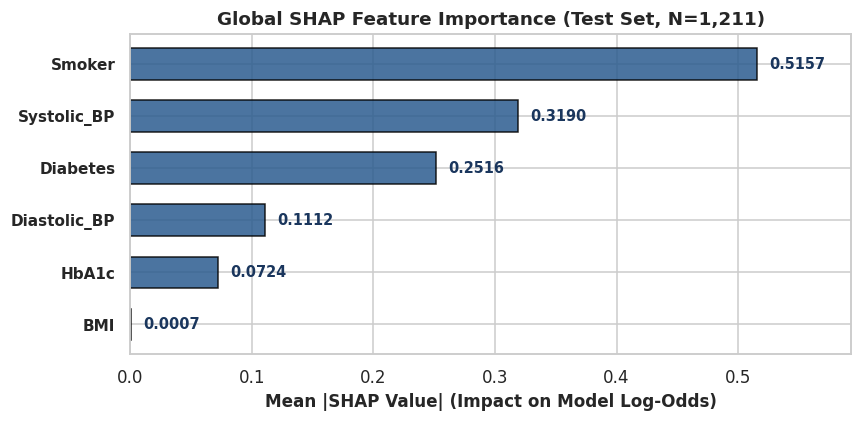

In [4]:
# Calculate mean absolute SHAP value per feature
mean_abs_shap = np.abs(exp.values).mean(axis=0)
shap_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean Absolute SHAP Value': mean_abs_shap
}).sort_values('Mean Absolute SHAP Value', ascending=False).reset_index(drop=True)

# Display table
display(shap_imp_df)

# Plot horizontal bar chart
plt.figure(figsize=(8, 4))
y_pos = np.arange(len(shap_imp_df))
plt.barh(y_pos, shap_imp_df['Mean Absolute SHAP Value'][::-1], color='#2b5c8f', edgecolor='black', alpha=0.85, height=0.6)
plt.yticks(y_pos, shap_imp_df['Feature'][::-1], fontsize=10, fontweight='bold')
plt.xlabel('Mean |SHAP Value| (Impact on Model Log-Odds)', fontsize=11, fontweight='bold')
plt.title('Global SHAP Feature Importance (Test Set, N=1,211)', fontsize=12, fontweight='bold')

for i, v in enumerate(shap_imp_df['Mean Absolute SHAP Value'][::-1]):
    plt.text(v + 0.01, i, f'{v:.4f}', va='center', fontsize=9.5, fontweight='bold', color='#1a365d')

plt.xlim(0, max(shap_imp_df['Mean Absolute SHAP Value']) * 1.15)
plt.tight_layout()
plt.show()

### Interpretation
Features with larger mean absolute SHAP values have a larger influence on the model's predictions. Smoker, Systolic_BP, and Diabetes contribute most strongly to the model predictions, while BMI contributes relatively little.

## 5. SHAP Summary / Beeswarm Plot
Visualize feature distributions and direction of impact on model log-odds across all test set patients.

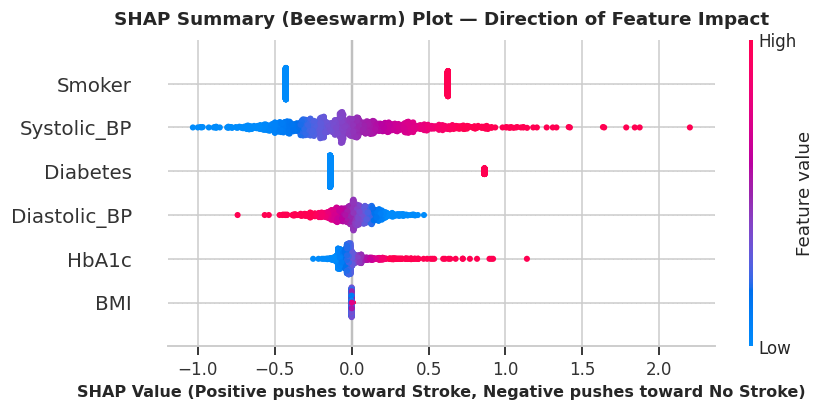

In [5]:
plt.figure(figsize=(9, 5))
shap.plots.beeswarm(exp, max_display=6, show=False)
plt.title('SHAP Summary (Beeswarm) Plot — Direction of Feature Impact', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('SHAP Value (Positive pushes toward Stroke, Negative pushes toward No Stroke)', fontsize=10.5, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation
Positive SHAP values push the model toward the Stroke class, while negative SHAP values push toward the No Stroke class. Lifetime smoking history, higher systolic blood pressure, and diabetes push predictions toward Stroke, while no smoking history, lower systolic BP, and absence of diabetes push predictions toward No Stroke.

## 6. Individual Prediction Explanations
Explain individual patient predictions across four representative test cases at the locked threshold $\tau = 0.45$:
1. True Positive (Case #24)
2. True Negative (Case #5)
3. False Positive (Case #1)
4. False Negative (Case #63)

### Case 1: True Positive (Case #24)
Correctly classified Stroke-history case.

Test Patient Index: 24
Raw Feature Values: {'Systolic_BP': 114.66666666666669, 'Diastolic_BP': 48.333333333333336, 'BMI': 33.1, 'Diabetes': 1.0, 'HbA1c': 7.3, 'Smoker': 1.0}
Predicted Probability: 0.8223 (Threshold = 0.45)
Actual Class: 1 (Stroke)
Predicted Class: 1 (Stroke)


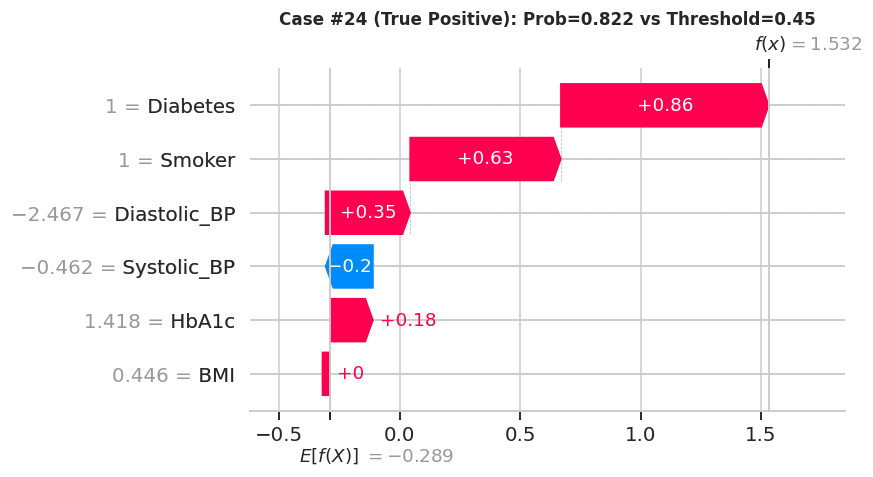

In [6]:
idx_tp = 24
prob_tp = clf.predict_proba(X_test_trans.iloc[[idx_tp]])[0, 1]
pred_tp = int(prob_tp >= 0.45)
actual_tp = int(y_test.iloc[idx_tp])
raw_tp = X_test.iloc[idx_tp].to_dict()

print(f"Test Patient Index: {idx_tp}")
print(f"Raw Feature Values: {raw_tp}")
print(f"Predicted Probability: {prob_tp:.4f} (Threshold = 0.45)")
print(f"Actual Class: {actual_tp} (Stroke)")
print(f"Predicted Class: {pred_tp} (Stroke)")

plt.figure(figsize=(8, 4))
shap.plots.waterfall(exp[idx_tp], show=False)
plt.title(f"Case #24 (True Positive): Prob={prob_tp:.3f} vs Threshold=0.45", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation
Diabetes (+0.86) and lifetime smoking history (+0.63) contributed positively toward the Stroke prediction, pushing the predicted probability to 0.822 (above threshold 0.45), while BMI contributed relatively little (+0.00).

### Case 2: True Negative (Case #5)
Correctly classified No Stroke case.

Test Patient Index: 5
Raw Feature Values: {'Systolic_BP': 110.66666666666669, 'Diastolic_BP': 63.0, 'BMI': 26.5, 'Diabetes': 0.0, 'HbA1c': 5.4, 'Smoker': 0.0}
Predicted Probability: 0.2620 (Threshold = 0.45)
Actual Class: 0 (No Stroke)
Predicted Class: 0 (No Stroke)


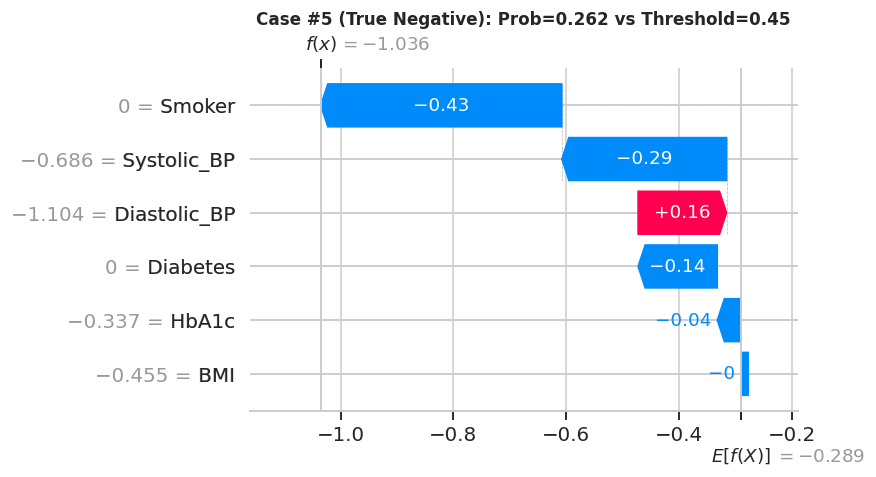

In [7]:
idx_tn = 5
prob_tn = clf.predict_proba(X_test_trans.iloc[[idx_tn]])[0, 1]
pred_tn = int(prob_tn >= 0.45)
actual_tn = int(y_test.iloc[idx_tn])
raw_tn = X_test.iloc[idx_tn].to_dict()

print(f"Test Patient Index: {idx_tn}")
print(f"Raw Feature Values: {raw_tn}")
print(f"Predicted Probability: {prob_tn:.4f} (Threshold = 0.45)")
print(f"Actual Class: {actual_tn} (No Stroke)")
print(f"Predicted Class: {pred_tn} (No Stroke)")

plt.figure(figsize=(8, 4))
shap.plots.waterfall(exp[idx_tn], show=False)
plt.title(f"Case #5 (True Negative): Prob={prob_tn:.3f} vs Threshold=0.45", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation
No lifetime smoking history (-0.43), normal systolic blood pressure (-0.29), and absence of diabetes (-0.14) pushed the model toward the No Stroke class, keeping the probability at 0.262 (well below threshold 0.45).

### Case 3: False Positive (Case #1)
Patient without reported stroke history classified as Stroke by the model.

Test Patient Index: 1
Raw Feature Values: {'Systolic_BP': 134.33333333333334, 'Diastolic_BP': 70.33333333333333, 'BMI': 23.3, 'Diabetes': 1.0, 'HbA1c': 6.7, 'Smoker': 0.0}
Predicted Probability: 0.6426 (Threshold = 0.45)
Actual Class: 0 (No Stroke)
Predicted Class: 1 (Stroke)


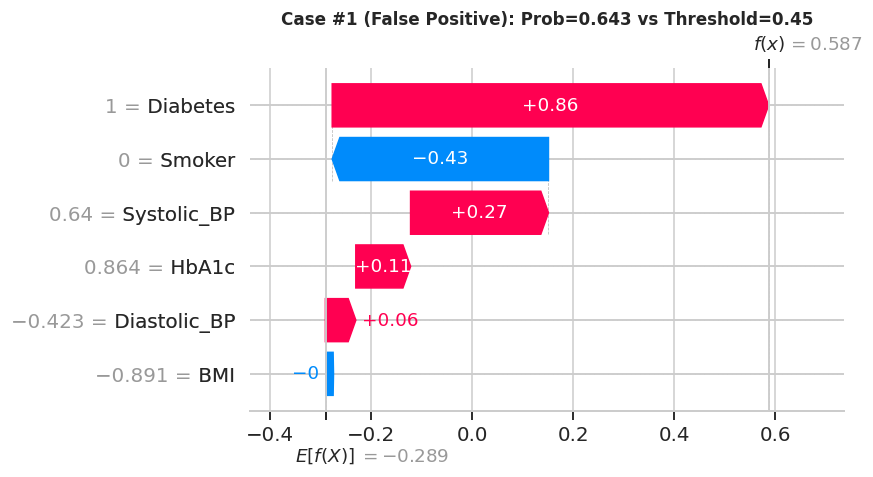

In [8]:
idx_fp = 1
prob_fp = clf.predict_proba(X_test_trans.iloc[[idx_fp]])[0, 1]
pred_fp = int(prob_fp >= 0.45)
actual_fp = int(y_test.iloc[idx_fp])
raw_fp = X_test.iloc[idx_fp].to_dict()

print(f"Test Patient Index: {idx_fp}")
print(f"Raw Feature Values: {raw_fp}")
print(f"Predicted Probability: {prob_fp:.4f} (Threshold = 0.45)")
print(f"Actual Class: {actual_fp} (No Stroke)")
print(f"Predicted Class: {pred_fp} (Stroke)")

plt.figure(figsize=(8, 4))
shap.plots.waterfall(exp[idx_fp], show=False)
plt.title(f"Case #1 (False Positive): Prob={prob_fp:.3f} vs Threshold=0.45", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation
Diabetes (+0.86) and elevated systolic blood pressure (+0.27) pushed the prediction above the 0.45 threshold (probability 0.643), resulting in a Stroke model classification despite no lifetime smoking history (-0.43).

### Case 4: False Negative (Case #63)
Patient with reported stroke history classified as No Stroke by the model.

Test Patient Index: 63
Raw Feature Values: {'Systolic_BP': 115.0, 'Diastolic_BP': 69.0, 'BMI': 31.0, 'Diabetes': 0.0, 'HbA1c': 6.1, 'Smoker': 0.0}
Predicted Probability: 0.2830 (Threshold = 0.45)
Actual Class: 1 (Stroke)
Predicted Class: 0 (No Stroke)


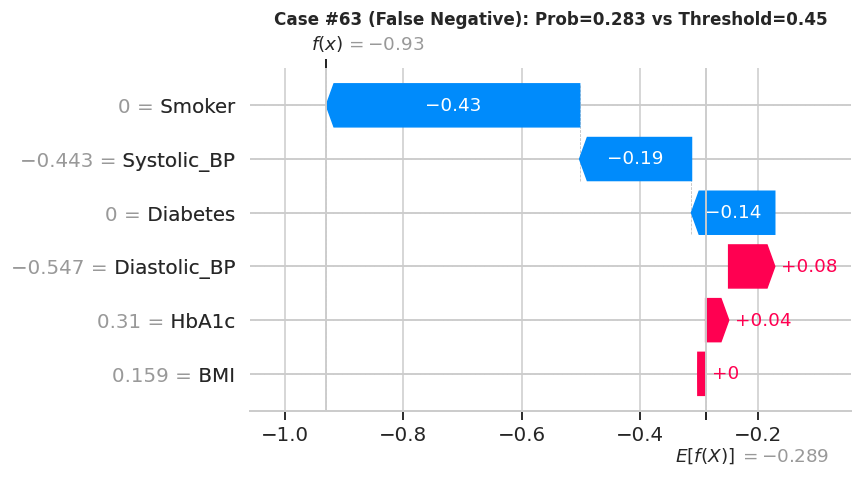

In [9]:
idx_fn = 63
prob_fn = clf.predict_proba(X_test_trans.iloc[[idx_fn]])[0, 1]
pred_fn = int(prob_fn >= 0.45)
actual_fn = int(y_test.iloc[idx_fn])
raw_fn = X_test.iloc[idx_fn].to_dict()

print(f"Test Patient Index: {idx_fn}")
print(f"Raw Feature Values: {raw_fn}")
print(f"Predicted Probability: {prob_fn:.4f} (Threshold = 0.45)")
print(f"Actual Class: {actual_fn} (Stroke)")
print(f"Predicted Class: {pred_fn} (No Stroke)")

plt.figure(figsize=(8, 4))
shap.plots.waterfall(exp[idx_fn], show=False)
plt.title(f"Case #63 (False Negative): Prob={prob_fn:.3f} vs Threshold=0.45", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation
No lifetime smoking history (-0.43), normal systolic blood pressure (-0.19), and absence of diabetes (-0.14) pushed the prediction toward the No Stroke class, keeping the probability at 0.283 (below threshold 0.45) and resulting in a No Stroke model classification.

## 7. Final SHAP Findings

| Feature | Mean |SHAP| | Model Impact Direction | Key Characteristic |
| :--- | :---: | :--- | :--- |
| **Smoker** | 0.5157 | Positive with lifetime smoking history (1), negative with no history (0) | Largest overall contributor in log-odds scale |
| **Systolic_BP** | 0.3190 | Positive with elevated BP, negative with normal BP | Primary continuous driver |
| **Diabetes** | 0.2516 | Strong positive shift with diabetes (1) | Major metabolic driver |
| **Diastolic_BP** | 0.1112 | Modest inverse shift after systolic BP adjustment | Secondary blood pressure component |
| **HbA1c** | 0.0724 | Positive with elevated glycemic values | Secondary glycemic indicator |
| **BMI** | 0.0007 | Minimal contribution | Negligible impact on model scores |

## 8. Phase 7 Conclusion
- SHAP LinearExplainer successfully explained the locked Phase 6 Logistic Regression model without altering dataset partitions, model parameters, or threshold (0.45).
- Lifetime smoking history, systolic blood pressure, and diabetes are the top three contributors to model predictions.
- Individual waterfall explanations clarify the exact feature contributions that drive decision-support outputs and model classifications.
- The explainability pipeline is validated and ready for integration into the Phase 8 Clinical Decision-Support prototype.